# Muon decays

### Simulating 1000 muon decays

The decay times of a set of 1000 muons will be simulated in an experimental situation.

Imagining there is a detector which traps or stops muons from the atmosphere. Once trapped, these muons hang around, and then decay according to an exponential decay time distribtuion, which a characteristics lifetime $\tau$. 
This means the distribution describing muon decay is an exponential function normalised to 1, where the muon lifetime is $\tau = 2.2$ microseconds.

P($t_i$|$\tau$) = $1/\tau$ exp(-$t_i$/$\tau$)

1000 random muon decay times will be produced by drawing from the above distribution in the range 0 < t < 10 microseconds. Meaning we lose decays that happen after a time window has closed.

In [421]:
# Import libraries
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.stats import norm

# Set a random seed for reproducibility
RANDOM_SEED = 42

In [302]:
# Define parameters
tau = 2.2

In [304]:
# Define the function to calculate the exponential decay
def exponential_decay(tau):

    return np.random.exponential(tau)

In [362]:
# Define a function to produce a set of random muon decay times
def generate_muon_decay_times(num_samples, tau):

    # Create a list to store values
    decay_times = []

    while len(decay_times) < num_samples:

        decay_time = exponential_decay(tau)

        if decay_time > 10:
            continue

        else:
            decay_times.append(decay_time)

    return decay_times

In [306]:
# Produce a set of 1000 random muon decay times
num_samples = 1000

# Now, run the function to generate 1000 random muon decay times
muon_decay_times = generate_muon_decay_times(num_samples, tau)


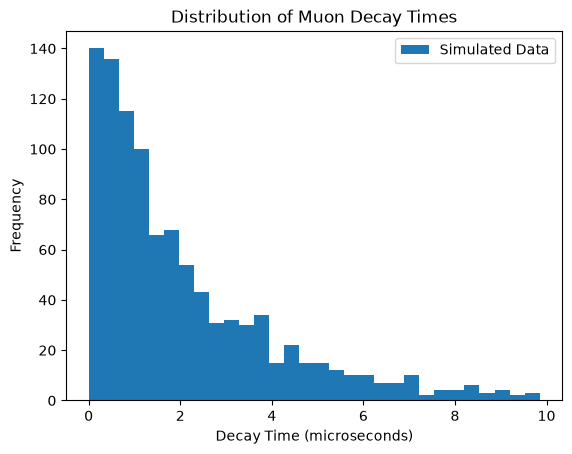

In [307]:
# Let's plot the values in a histogram to check it has an exponential shape
# Normalise the histogram to have a total area of 1
plt.hist(muon_decay_times, bins = 30, label='Simulated Data') #density = True)
plt.xlabel('Decay Time (microseconds)')
plt.ylabel('Frequency')
plt.title('Distribution of Muon Decay Times')
plt.legend()
plt.show()

We can see there is an exponential shape as expected.


### Estimating the lifetime

Now, consider the data set to be as if we had observed it in the real laboratory experiment. This means we have recorded 1000 muon decay times, but we would not know what the original muon lifetime was.

So, estimate the lifetime from the dataset above. By definition this is the estimate of $\tau$ = the average of all measured decay times

In [308]:
def estimate_tau(muon_decay_times):

    # Estimate the mean and standard deviation of the decay times
    mean_decay_time = np.mean(muon_decay_times)
    std_decay_time = np.std(muon_decay_times)
    
    return mean_decay_time, std_decay_time

In [309]:
# Estimate tau
tau_estimate, tau_std = estimate_tau(muon_decay_times)

# Print the results
print(f"Estimated Mean Decay Time: {tau_estimate:.2f} microseconds")
print(f"Estimated Standard Deviation: {tau_std:.2f} microseconds")

Estimated Mean Decay Time: 2.05 microseconds
Estimated Standard Deviation: 1.99 microseconds


This value is close to the known original value of 2.2 microseconds.

### What is the precision?

Now, this process will be repeated in order to simualte the whole experiment 500 times. In each case, a value of $\tau$ will be obtained and the final distribution will be plotted.

In [395]:
# Create a list to hold all the values
tau_estimates = []
tau_stds = []

# Define parameters
num_samples = 1000
tau = 2.2

# Iterate 500 times
for t in range(0, 500):

    # Generate 1000 random muon decays
    muon_decay_times = generate_muon_decay_times(num_samples, tau)

    # Estimate tau
    tau_estimate, tau_std = estimate_tau(muon_decay_times)

    tau_estimates.append(tau_estimate)
    tau_stds.append(tau_std)

In [405]:
# Print the mean tau estimate from this distribution
# This is the mean of the Gaussian distribution
mean_tau_estimate = np.mean(tau_estimates)
std_tau_estimate = np.std(tau_estimates)

print(f"Estimated mean tau estimate: {mean_tau_estimate:.2f} microseconds")
print(f"Estimated tau standard deviation estimate: {std_tau_estimate:.2f} microseconds")

Estimated mean tau estimate: 2.10 microseconds
Estimated tau standard deviation estimate: 0.06 microseconds


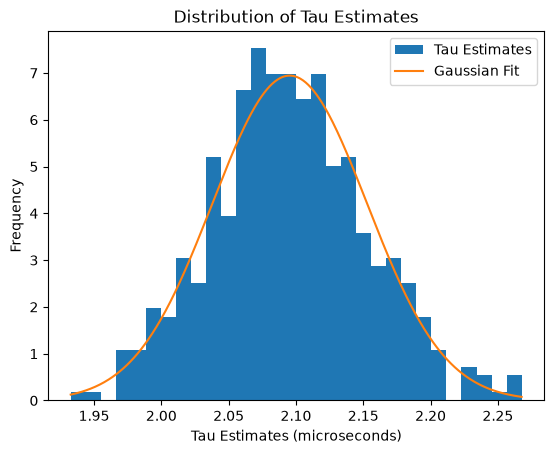

In [412]:
# Plot the distribution of all the values of taus
plt.hist(tau_estimates, bins = 30, label='Tau Estimates', density = True)

# Fit a Gaussian distribution to the model
x = np.linspace(min(tau_estimates), max(tau_estimates), 500)
y = norm.pdf(x, loc = np.mean(tau_estimates), scale = np.std(tau_estimates))

# Plot the Gaussian distribution
plt.plot(x, y, label = "Gaussian Fit")

# Add labels
plt.xlabel('Tau Estimates (microseconds)')
plt.ylabel('Frequency')
plt.title('Distribution of Tau Estimates')
plt.legend()
plt.show()

### Let's calculate the chi-squared

In [406]:
# Create the histogram
num_bins = 30
counts, bin_edges = np.histogram(tau_estimates, bins = num_bins)
n_total = len(tau_estimates)

In [407]:
# Integrate unbinned PDF between bin edges to get the binned model
# P(bin) = CDF(right edge) - CDF(left edge)
bin_probs = np.diff(norm.cdf(bin_edges, loc = mean_tau_estimate, scale = std_tau_estimate))
expected_counts = n_total * bin_probs

In [408]:
# Calculate uncertainty
# Poisson counting statistics: sigma = sqrt(counts)
uncertainties = np.sqrt(expected_counts)

In [409]:
# Define a function to calculate chi squared
def calculate_chi_squared(data, model, data_uncertainty):

    data = np.array(data)
    model = np.array(model)
    data_uncertainty = np.array(data_uncertainty)

    chi_squared = np.sum(((data - model) / data_uncertainty) ** 2)

    return chi_squared

In [411]:
# Calculate chi-squared 
chi_squared = calculate_chi_squared(counts, expected_counts, uncertainties)

# Print chi-squared
print(f"Chi-squared: {chi_squared}")

Chi-squared: 30.329790949573557


We expect chi-squared to be ~ (number of data points - number of parameters in the model). This would mean the model describes the data well. 

If chi-squared is much greater than this, the model describe the data poorly. 

If chi-squared is much smaller than this, it suggests the data has uncertainties which are overestimated.

In [377]:
# Calcualte expected chi-squared
# Number of parameters = 2
expected_chi_squared = len(counts) - 2 

# Print expected chi-squared
print(f"Expected chi-squared: {expected_chi_squared:.2f}")

Expected chi-squared: 28.00


This means that our model roughly describes our data well!

###

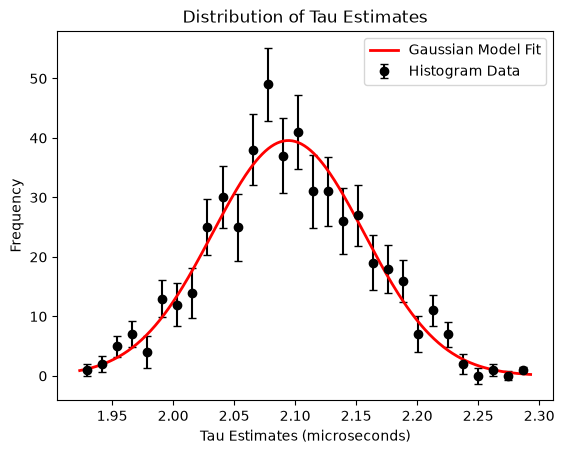

In [388]:
# Plot the data points and error bars
plt.errorbar(bin_centers, counts, yerr = uncertainties, fmt = 'o', color = 'black', 
             capsize=3, label='Histogram Data')

# Plot the Gaussian distribution
x = np.linspace(bin_edges[0], bin_edges[-1], 300)
gaussian = norm.pdf(x, loc = mean_tau_estimate, scale = std_tau_estimate)
y = total_samples * bin_width * gaussian
plt.plot(x, y, 'r-', lw=2, label='Gaussian Model Fit')

# Add labels
plt.xlabel(r'Tau Estimates (microseconds)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Tau Estimates')
plt.legend()
plt.show()

### Let's calculate the liklihood

In [414]:
# Calculate the log likelihood values
log_likelihood_values = norm.logpdf(tau_estimates, loc = mean_tau_estimate, scale = std_tau_estimate)
total_log_likelihood = np.sum(log_likelihood_values)
nll = - total_log_likelihood
two_nll = 2 * nll

# Print values
print(f"Log likelihood: {total_log_likelihood:.2f}")
print(f"Negative log likelihood: {nll:.2f}")
print(f"2 * NLL: {two_nll:.2f}")

Log likelihood: 718.89
Negative log likelihood: -718.89
2 * NLL: -1437.78


In [415]:
def negative_log_likelihood(params, data):

    mu, sigma = params

    return - np.sum(norm.logpdf(data, loc = mu, scale = sigma))

In [424]:
# Initial guess
initial_guess = [mean_tau_estimate, std_tau_estimate]

# Minimise NLL using scipy
result = scipy.optimize.minimize(negative_log_likelihood, initial_guess, args = (tau_estimates,))

# Obtain parameters
fit_mu, fit_sigma = result.x
minimised_nll = result.fun

# Print values
print(f"Optimised mu: {fit_mu:.2f}")
print(f"Optimised sigma: {fit_sigma:.2f}")
print(f"Minimised NLL: {minimised_nll:.2f}")
print(f"2 * NLL: {2 * minimised_nll:.2f}")

Optimised mu: 2.10
Optimised sigma: 0.06
Minimised NLL: -718.89
2 * NLL: -1437.78


#### How well (with what numerical precision) can you expect to esimate the true lifetime from any single experiment?
The standard deviation of this distribution is the statistical uncertainty in our real measurement.


#### Is the method biased? What is the bias and precision on the bias?

Since we are running multiple toys (eg. running an experiment many times), it introduces a statisical bias on the result. This is because it treats every toy as if it has the same weight or frequency. This is known as a sampling bias or a failure to use a weighted mean. 

The expected bias in our real measurement is the mean of the distribution and the true value.